# EDA03 — Linha 3 (2024 e 2025), sensores de 15 cm e 30 cm

**Objetivo:** entender como a umidade do solo responde à irrigação e à secagem na linha 3, com os dois sensores de profundidade analisados separadamente, e montar uma base para um classificador de "irrigar ou não".

**Por que a linha 3:** nela a irrigação é acionada pela umidade do solo (confirmado na seção 6), que é o tipo de decisão que o nosso sistema vai tomar.

**Por que separar os sensores:** cada linha tem um sensor a 15 cm e outro a 30 cm. Eles reagem de forma bem diferente, e juntar os dois (como no EDA02) esconde isso.

**Dados:** cultivo de tomate em campo aberto na Azienda Sperimentale Stuard, em Parma (Itália). Arquivo `data/IoT Dataset from an Evolving Tomato Cultivation Te.zip`, extraído dentro de `data/`. Todas as tabelas e figuras são salvas em `outputs/eda03_linha3/`.

**Próximo notebook:** `codes/linha3 - umidade/modelo_linha3/modelo_irrigacao.ipynb`, que treina o modelo com as decisões tiradas daqui e prepara o uso em Fortaleza.

## 0. Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)

NOME_DATASET = "IoT Dataset from an Evolving Tomato Cultivation Te"

# sobe as pastas até achar a raiz do repositório (a que tem data/)
BASE_DIR = Path.cwd().resolve()
while not (BASE_DIR / "data").is_dir() and BASE_DIR != BASE_DIR.parent:
    BASE_DIR = BASE_DIR.parent

DATA_DIR = BASE_DIR / "data" / NOME_DATASET / NOME_DATASET
OUTPUT_DIR = BASE_DIR / "outputs" / "eda03_linha3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ANOS = [2024, 2025]
LINHA = 3
FUSO = "Europe/Rome"  # o cultivo fica em Parma (Itália); ts_generation vem em UTC
FREQ = "10min"        # todos os sensores leem a cada ~10 min
PROFS = ["15cm", "30cm"]
CORES = {"15cm": "tab:blue", "30cm": "tab:brown"}

In [2]:
def carregar(ano, nome):
    """Lê {nome}{ano}.csv e cria a coluna datetime no horário local."""
    df = pd.read_csv(DATA_DIR / str(ano) / f"{nome}{ano}.csv")
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    # o hidrômetro de 2024 chama o ID de device_identifier
    df = df.rename(columns={"device_identifier": "generated_by"})
    df["datetime"] = (
        pd.to_datetime(df["ts_generation"], unit="ms", utc=True)
        .dt.tz_convert(FUSO)
        .dt.as_unit("us")
    )
    return df.sort_values("datetime").reset_index(drop=True)


def salvar_fig(fig, nome):
    fig.savefig(OUTPUT_DIR / nome, dpi=150, bbox_inches="tight")


def salvar_csv(df, nome, index=False):
    df.to_csv(OUTPUT_DIR / nome, index=index)


def vpd(temp, ur):
    """Déficit de pressão de vapor do ar (kPa), equação de Tetens."""
    es = 0.6108 * np.exp(17.27 * temp / (temp + 237.3))
    return es * (1 - ur / 100)

## 1. Carregamento

Só os arquivos que importam para o problema: solo, válvula, hidrômetro e ambiente. Solo, válvula e hidrômetro são filtrados para a linha 3. O sensor ambiental é único para o campo todo.

In [3]:
dados = {}

for ano in ANOS:
    soil = carregar(ano, "soil")
    valve = carregar(ano, "valve_controller")
    water = carregar(ano, "water_meter")

    dados[ano] = {
        "soil": soil[soil["line"] == LINHA].copy(),
        "valve": valve[valve["line"] == LINHA].copy(),
        "water": water[water["line"] == LINHA].copy(),
        "env": carregar(ano, "environmental"),
    }

pd.DataFrame([
    {
        "ano": ano,
        "arquivo": nome,
        "registros": len(df),
        "inicio": f"{df['datetime'].min():%Y-%m-%d}",
        "fim": f"{df['datetime'].max():%Y-%m-%d}",
    }
    for ano, d in dados.items()
    for nome, df in d.items()
])

,ano,arquivo,registros,inicio,fim
0,2024,soil,26764,2024-06-11,2024-09-23
1,2024,valve,11658,2024-06-12,2024-09-05
2,2024,water,13186,2024-06-10,2024-10-01
3,2024,env,9327,2024-06-12,2024-09-05
4,2025,soil,39781,2025-06-01,2025-11-03
5,2025,valve,22692,2025-06-06,2025-12-12
6,2025,water,26855,2025-06-01,2026-01-12
7,2025,env,17318,2025-06-26,2025-10-28


## 2. Qual sensor está a 15 cm e qual está a 30 cm

O README do dataset diz que cada linha tem um sensor a 15 cm e outro a 30 cm, mas não diz qual ID é qual.

Dá para descobrir pela temperatura do solo: a variação diária de temperatura diminui com a profundidade. O sensor com maior amplitude térmica diária é o mais raso.

In [4]:
evid = []
curvas = {}

for ano in ANOS:
    soil = dados[ano]["soil"].copy()
    soil["data"] = soil["datetime"].dt.date
    soil["hora"] = soil["datetime"].dt.hour

    for sensor, s in soil.groupby("generated_by"):
        curvas[(ano, sensor)] = s.groupby("hora")["temperature"].mean()
        evid.append({
            "ano": ano,
            "sensor": sensor[:4],
            "amplitude_termica_diaria_C": s.groupby("data")["temperature"].agg(lambda x: x.max() - x.min()).median(),
            "desvio_temperatura_C": s["temperature"].std(),
            "umidade_mediana": s["humidity"].median(),
            "sensor_id": sensor,
        })

evid = pd.DataFrame(evid)

# maior amplitude térmica = mais raso
mais_raso = evid.groupby("ano")["amplitude_termica_diaria_C"].transform("max") == evid["amplitude_termica_diaria_C"]
evid["profundidade"] = np.where(mais_raso, "15cm", "30cm")

assert evid.groupby("sensor_id")["profundidade"].nunique().max() == 1, "os anos discordam sobre a profundidade"

SENSORES = dict(zip(evid["sensor_id"], evid["profundidade"]))

for ano in ANOS:
    dados[ano]["soil"]["profundidade"] = dados[ano]["soil"]["generated_by"].map(SENSORES)

salvar_csv(evid, "02_evidencia_profundidade.csv")
evid.drop(columns="sensor_id")

,ano,sensor,amplitude_termica_diaria_C,desvio_temperatura_C,umidade_mediana,profundidade
0,2024,2f2b,0.8,2.04,25.51,30cm
1,2024,901b,2.2,2.48,27.36,15cm
2,2025,2f2b,0.5,2.36,31.13,30cm
3,2025,901b,1.2,2.65,28.47,15cm


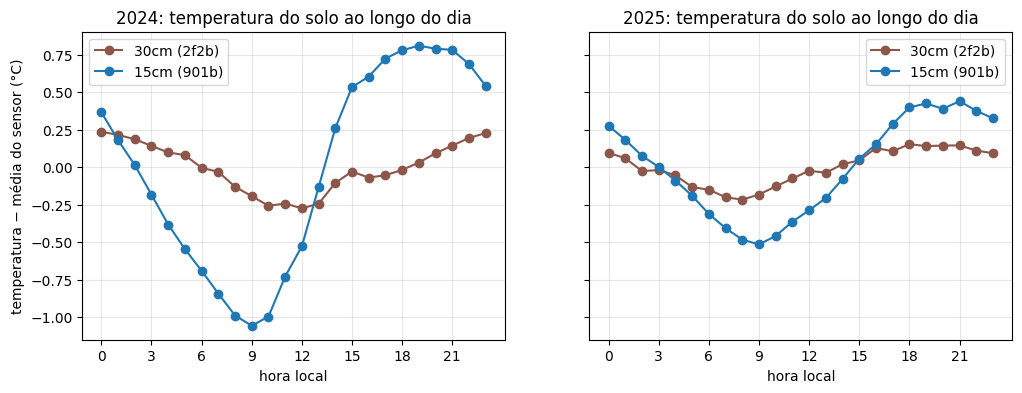

In [5]:
fig, eixos = plt.subplots(1, len(ANOS), figsize=(12, 4), sharey=True)

for ax, ano in zip(eixos, ANOS):
    for sensor, prof in SENSORES.items():
        c = curvas[(ano, sensor)]
        ax.plot(c.index, c - c.mean(), marker="o", color=CORES[prof], label=f"{prof} ({sensor[:4]})")
    ax.set(title=f"{ano}: temperatura do solo ao longo do dia", xlabel="hora local", xticks=range(0, 24, 3))
    ax.grid(alpha=0.3)
    ax.legend()

eixos[0].set_ylabel("temperatura − média do sensor (°C)")
salvar_fig(fig, "02_evidencia_profundidade.png")
plt.show()

O sensor `901b` varia 2,2 °C por dia em 2024 e 1,2 °C em 2025. O `2f2b` varia 0,8 e 0,5 °C. A ordem é a mesma nos dois anos, então:

- `901b` → 15 cm
- `2f2b` → 30 cm

A seção 7 confirma: o sensor de 15 cm é sempre o primeiro a reagir à irrigação.

## 3. Período válido

Antes e depois da temporada os sensores ficam fora do solo e marcam perto de 0%. Esses dias distorcem qualquer estatística, então são descartados.

Critério: o dia é válido se os dois sensores tiverem mediana diária acima de 5% e pelo menos 72 leituras (metade do dia).

In [6]:
UMIDADE_MINIMA = 5.0
LEITURAS_MINIMAS = 72

diarios = []

for ano in ANOS:
    soil = dados[ano]["soil"].assign(data=lambda d: d["datetime"].dt.date)

    d = soil.groupby(["data", "profundidade"])["humidity"].agg(["median", "count"]).unstack("profundidade")
    d.columns = [f"{estat}_{prof}" for estat, prof in d.columns]

    d["valido"] = True
    for prof in PROFS:
        d["valido"] &= (d[f"median_{prof}"].fillna(0) > UMIDADE_MINIMA) & (d[f"count_{prof}"].fillna(0) >= LEITURAS_MINIMAS)

    d["ano"] = ano
    diarios.append(d.reset_index())

diario = pd.concat(diarios, ignore_index=True)
DIAS_VALIDOS = set(diario.loc[diario["valido"], "data"])

salvar_csv(diario, "03_dias_validos.csv")

diario[diario["valido"]].groupby("ano")["data"].agg(dias_validos="size", primeiro="min", ultimo="max")

,dias_validos,primeiro,ultimo
ano,,,
2024,88,2024-06-13,2024-09-16
2025,88,2025-06-26,2025-09-23


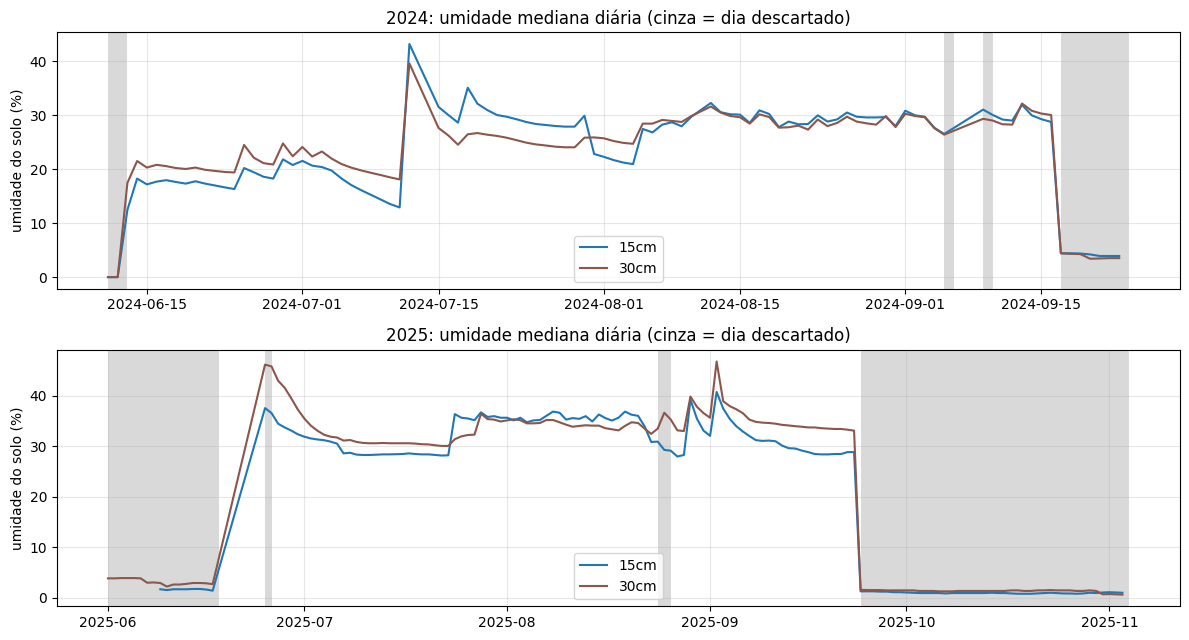

In [7]:
fig, eixos = plt.subplots(len(ANOS), 1, figsize=(12, 6.5))

for ax, ano in zip(eixos, ANOS):
    d = diario[diario["ano"] == ano].assign(data=lambda x: pd.to_datetime(x["data"]))
    for prof in PROFS:
        ax.plot(d["data"], d[f"median_{prof}"], color=CORES[prof], label=prof)
    for dia in d.loc[~d["valido"], "data"]:
        ax.axvspan(dia, dia + pd.Timedelta("1D"), color="0.85", lw=0)
    ax.set(title=f"{ano}: umidade mediana diária (cinza = dia descartado)", ylabel="umidade do solo (%)")
    ax.grid(alpha=0.3)
    ax.legend()

fig.tight_layout()
salvar_fig(fig, "03_periodo_valido.png")
plt.show()

Ficam 88 dias por ano: de 13/06 a 16/09 em 2024 e de 26/06 a 23/09 em 2025. Em 2025 os sensores continuam enviando dados até novembro, mas marcando ~1%: já é o fim da temporada.

## 4. Série integrada em grade de 10 min

Cada sensor é reamostrado para a mesma grade de 10 min, então cada linha da tabela é um instante com todas as variáveis lado a lado. Esse é o formato que o modelo vai usar.

- **válvula:** 1 se esteve aberta em algum momento do bloco de 10 min;
- **hidrômetro:** o valor é acumulado, então o volume aplicado é a diferença entre leituras;
- **VPD:** déficit de pressão de vapor, calculado a partir da temperatura e da umidade do ar. Resume em um número a "demanda de água" da atmosfera e pode ser calculado com os sensores do protótipo.

In [8]:
series = []

for ano in ANOS:
    d = dados[ano]

    solo = (
        d["soil"].set_index("datetime")
        .groupby("profundidade")[["humidity", "temperature", "electrical_conductivity"]]
        .resample(FREQ).mean()
        .unstack("profundidade")
    )
    nomes = {"humidity": "umidade", "temperature": "temp_solo", "electrical_conductivity": "ce"}
    solo.columns = [f"{nomes[var]}_{prof}" for var, prof in solo.columns]

    valvula = d["valve"].set_index("datetime")["valve_state"].resample(FREQ).max().ffill(limit=1)

    volume = d["water"].set_index("datetime")["current_volume"].resample(FREQ).last().ffill().diff()
    volume[volume < 0] = np.nan

    amb = (
        d["env"].set_index("datetime")[["temperature", "humidity", "co2"]]
        .resample(FREQ).mean()
        .rename(columns={"temperature": "ar_temperatura", "humidity": "ar_umidade", "co2": "ar_co2"})
    )
    amb["vpd_kpa"] = vpd(amb["ar_temperatura"], amb["ar_umidade"])

    s = pd.concat([solo, valvula.rename("valvula"), volume.rename("volume_aplicado"), amb], axis=1, sort=True)
    s = s.loc[solo.index.min():solo.index.max()]
    s["ano"] = ano
    series.append(s)

serie = pd.concat(series)
serie.index.name = "datetime"
serie["valido"] = pd.Series(serie.index.date, index=serie.index).isin(DIAS_VALIDOS)

salvar_csv(serie.reset_index(), "04_serie_integrada_linha3_10min.csv")

print(f"{len(serie)} instantes, {serie['valido'].sum()} em dias válidos")
print("Cobertura no período válido (% de instantes com dado):")
(serie[serie["valido"]].drop(columns="valido").groupby("ano").agg(lambda c: 100 * c.notna().mean()).T.round(1))

37393 instantes, 25344 em dias válidos
Cobertura no período válido (% de instantes com dado):


ano,2024,2025
umidade_15cm,97.1,97.3
umidade_30cm,96.2,97.3
temp_solo_15cm,97.1,97.3
temp_solo_30cm,96.2,97.3
ce_15cm,97.1,97.3
ce_30cm,96.2,97.3
valvula,90.1,98.9
volume_aplicado,100.0,99.9
ar_temperatura,72.4,97.4
ar_umidade,72.3,97.4


Solo, válvula e hidrômetro cobrem mais de 90% do período nos dois anos. O sensor ambiental cobre só 72% em 2024, porque para de enviar dados em 05/09. Modelos que usam variáveis do ar perdem essa parte de 2024.

## 5. Eventos de irrigação

- **pulso:** sequência contínua de leituras com a válvula aberta. A válvula reporta a cada ~10 min, então a duração é aproximada;
- **episódio:** pulsos separados por menos de 60 min. Na linha 3 o controlador repete pulsos de ~30 min até a umidade subir, e isso conta como um único episódio.

In [9]:
INTERVALO_EPISODIO_MIN = 60


def extrair_pulsos(valve):
    v = valve.sort_values("datetime").reset_index(drop=True)
    aberta = v["valve_state"] > 0
    bloco = (aberta != aberta.shift()).cumsum()

    pulsos = v[aberta].groupby(bloco[aberta])["datetime"].agg(inicio="min", ultima_aberta="max").reset_index(drop=True)

    # fim = primeira leitura fechada depois da última aberta
    fechadas = v.loc[~aberta, "datetime"].reset_index(drop=True)
    pulsos["fim"] = fechadas.reindex(fechadas.searchsorted(pulsos["ultima_aberta"], side="right")).reset_index(drop=True)
    pulsos["duracao_min"] = (pulsos["fim"] - pulsos["inicio"]).dt.total_seconds() / 60

    return pulsos.drop(columns="ultima_aberta")


def volume_por_pulso(pulsos, water):
    w = water[["datetime", "current_volume"]]
    antes = pd.merge_asof(pulsos[["inicio"]], w, left_on="inicio", right_on="datetime",
                          direction="backward", tolerance=pd.Timedelta("30min"))["current_volume"]
    depois = pd.merge_asof(pulsos[["fim"]] + pd.Timedelta("10min"), w, left_on="fim", right_on="datetime",
                           direction="forward", tolerance=pd.Timedelta("30min"))["current_volume"]
    return (depois - antes).to_numpy()


partes = []

for ano in ANOS:
    p = extrair_pulsos(dados[ano]["valve"])
    intervalo = (p["inicio"] - p["fim"].shift()).dt.total_seconds() / 60
    p["episodio"] = [f"{ano}_{n:03d}" for n in (intervalo.isna() | (intervalo > INTERVALO_EPISODIO_MIN)).cumsum()]
    p["volume"] = volume_por_pulso(p, dados[ano]["water"])
    p["ano"] = ano
    p["dia_valido"] = p["inicio"].dt.date.isin(DIAS_VALIDOS)
    partes.append(p)

pulsos = pd.concat(partes, ignore_index=True)
salvar_csv(pulsos, "05_pulsos_irrigacao_linha3.csv")

pulsos.groupby("ano").agg(
    pulsos=("inicio", "size"),
    episodios=("episodio", "nunique"),
    duracao_mediana_min=("duracao_min", "median"),
    volume_mediano_por_pulso=("volume", "median"),
    pulsos_em_dias_validos=("dia_valido", "sum"),
)

,pulsos,episodios,duracao_mediana_min,volume_mediano_por_pulso,pulsos_em_dias_validos
ano,,,,,
2024,74,49,29.89,262.0,74
2025,75,58,29.89,188.0,74


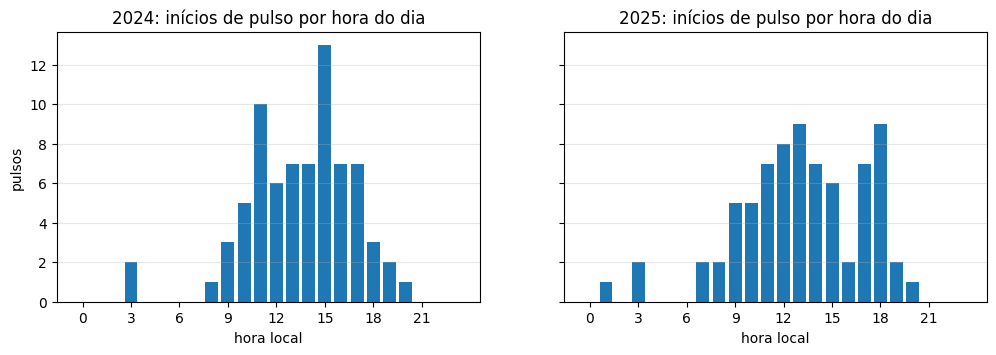

In [10]:
fig, eixos = plt.subplots(1, len(ANOS), figsize=(12, 3.5), sharey=True)

for ax, ano in zip(eixos, ANOS):
    contagem = pulsos.loc[pulsos["ano"] == ano, "inicio"].dt.hour.value_counts().reindex(range(24), fill_value=0)
    ax.bar(contagem.index, contagem, color="tab:blue")
    ax.set(title=f"{ano}: inícios de pulso por hora do dia", xlabel="hora local", xticks=range(0, 24, 3))
    ax.grid(alpha=0.3, axis="y")

eixos[0].set_ylabel("pulsos")
salvar_fig(fig, "05_inicios_por_hora.png")
plt.show()

São ~75 pulsos por ano. Os disparos se espalham ao longo do dia, com mais frequência à tarde, quando o solo seca mais rápido.

Na linha 3 quase todos os pulsos duram ~30 min, e um episódio tem em média 1,3 a 1,5 pulso (no máximo 9). O volume mediano por pulso é 262 (2024) e 188 (2025) na unidade do hidrômetro. O README diz que essa unidade é m³, mas isso não combina com a escala do contador. Vale confirmar.

## 6. Qual é a regra do controlador da linha 3

Se a irrigação dispara quando um sensor cruza um limiar, a umidade desse sensor no início dos pulsos deve se concentrar perto de um valor fixo. Isso precisa aparecer muito mais nos disparos do que nas leituras em geral; senão é só um valor comum do sensor.

In [11]:
# última leitura de cada profundidade antes do início de cada pulso
partes = []

for ano in ANOS:
    p = pulsos[pulsos["ano"] == ano]
    for prof in PROFS:
        s = dados[ano]["soil"].query("profundidade == @prof")[["datetime", "humidity"]]
        p = pd.merge_asof(p, s.rename(columns={"humidity": f"umidade_{prof}"}), left_on="inicio", right_on="datetime",
                          direction="backward", tolerance=pd.Timedelta("20min")).drop(columns="datetime")
    partes.append(p)

pulsos = pd.concat(partes, ignore_index=True)
pulsos["mes"] = pulsos["inicio"].dt.month

pulsos.groupby(["ano", "mes"])[[f"umidade_{p}" for p in PROFS]].agg(["count", "median", "min", "max"])

umidade_15cm                      umidade_30cm                     
                count median    min    max        count median    min    max
ano  mes                                                                    
2024 7             23  27.98  12.81  47.05           23  23.98  17.44  26.42
     8             47  26.84  20.90  40.55           47  26.90  23.88  29.56
     9              4  27.05  27.02  27.24            4  26.90  26.90  26.90
2025 6              2  34.95  34.47  35.43            3  42.34   3.97  43.79
     7             23  33.93  28.03  35.81           23  31.90  30.07  34.75
     8             49  33.93  33.66  35.96           49  34.03  32.87  34.91

In [12]:
concentracao = []

for ano in ANOS:
    disparos = pulsos[(pulsos["ano"] == ano) & pulsos["dia_valido"]]
    leituras = serie[(serie["ano"] == ano) & serie["valido"]]

    for prof in PROFS:
        u = disparos[f"umidade_{prof}"].dropna()
        valor = u.round(1).mode().iloc[0]
        concentracao.append({
            "ano": ano,
            "profundidade": prof,
            "valor_mais_frequente_no_disparo": valor,
            "pct_disparos_perto (±0.5)": 100 * ((u - valor).abs() <= 0.5).mean(),
            "pct_leituras_perto (±0.5)": 100 * ((leituras[f"umidade_{prof}"] - valor).abs() <= 0.5).mean(),
        })

concentracao = pd.DataFrame(concentracao)
concentracao["razao"] = concentracao["pct_disparos_perto (±0.5)"] / concentracao["pct_leituras_perto (±0.5)"]

# em cada ano, o sensor de gatilho é o de maior concentração nos disparos
gatilho = concentracao.loc[concentracao.groupby("ano")["pct_disparos_perto (±0.5)"].idxmax()].set_index("ano")

salvar_csv(concentracao, "06_concentracao_disparo.csv")
concentracao

,ano,profundidade,valor_mais_frequente_no_disparo,pct_disparos_perto (±0.5),pct_leituras_perto (±0.5),razao
0,2024,15cm,27.0,31.08,6.52,4.77
1,2024,30cm,26.9,58.11,9.59,6.06
2,2025,15cm,33.9,82.43,9.17,8.99
3,2025,30cm,34.2,47.30,23.83,1.98


Olhando a série dia a dia, aparece um detalhe: no começo de cada temporada o solo passa semanas abaixo do valor de disparo sem nenhuma irrigação. Nesse período o controlador automático ainda não estava funcionando.

Por isso defino a **fase automática** como a maior sequência de dias com irrigação sem pausas de mais de 3 dias. A regra é testada no período válido inteiro e só dentro dessa fase.

In [13]:
def fase_automatica(pulsos, max_pausa_dias=3):
    fases = {}
    for ano, p in pulsos[pulsos["dia_valido"]].groupby("ano"):
        dias = pd.Series(sorted(p["inicio"].dt.normalize().unique()))
        grupo = (dias.diff().dt.days > max_pausa_dias).cumsum()
        maior = dias.groupby(grupo).agg(["min", "max", "size"]).sort_values("size").iloc[-1]
        fases[ano] = (maior["min"], maior["max"] + pd.Timedelta("1D") - pd.Timedelta("1s"))
    return fases


FASES = fase_automatica(pulsos)

for ano, (ini, fim) in FASES.items():
    print(f"{ano}: fase automática de {ini:%d/%m} a {fim:%d/%m}")

2024: fase automática de 04/08 a 03/09
2025: fase automática de 23/07 a 19/08


In [14]:
verificacao = []

for ano, g in gatilho.iterrows():
    prof, limiar = g["profundidade"], g["valor_mais_frequente_no_disparo"]
    s_ano = serie[(serie["ano"] == ano) & serie["valido"]]

    for periodo, s in [("período válido", s_ano), ("fase automática", s_ano.loc[FASES[ano][0]:FASES[ano][1]])]:
        abaixo = s[f"umidade_{prof}"] <= limiar + 0.1
        cruzou = abaixo & ~abaixo.shift(fill_value=True)
        # válvula aberta agora ou nos próximos 40 min
        irriga = s["valvula"].fillna(0)[::-1].rolling(5, min_periods=1).max()[::-1] > 0

        verificacao.append({
            "ano": ano,
            "periodo": periodo,
            "regra": f"umidade_{prof} <= {limiar}",
            "% tempo abaixo": 100 * abaixo.mean(),
            "P(irriga | abaixo)": 100 * irriga[abaixo].mean(),
            "P(irriga | acima)": 100 * irriga[~abaixo].mean(),
            "cruzamentos p/ baixo": cruzou.sum(),
            "P(irriga | cruzou)": 100 * irriga[cruzou].mean(),
        })

verificacao = pd.DataFrame(verificacao)
salvar_csv(verificacao, "06_regra_limiar.csv")

# resumo da regra, usado pelo notebook do modelo
regra_controlador = pd.DataFrame([
    {"ano": ano, "sensor": g["profundidade"], "limiar": g["valor_mais_frequente_no_disparo"],
     "fase_inicio": FASES[ano][0], "fase_fim": FASES[ano][1]}
    for ano, g in gatilho.iterrows()
])
salvar_csv(regra_controlador, "06_regra_controlador.csv")

verificacao

,ano,periodo,regra,% tempo abaixo,P(irriga | abaixo),P(irriga | acima),cruzamentos p/ baixo,P(irriga | cruzou)
0,2024,período válido,umidade_30cm <= 26.9,55.15,3.98,3.68,174,24.14
1,2024,fase automática,umidade_30cm <= 26.9,5.39,63.52,5.04,42,97.62
2,2025,período válido,umidade_15cm <= 33.9,57.47,2.79,5.68,199,29.15
3,2025,fase automática,umidade_15cm <= 33.9,6.50,75.57,7.72,59,98.31


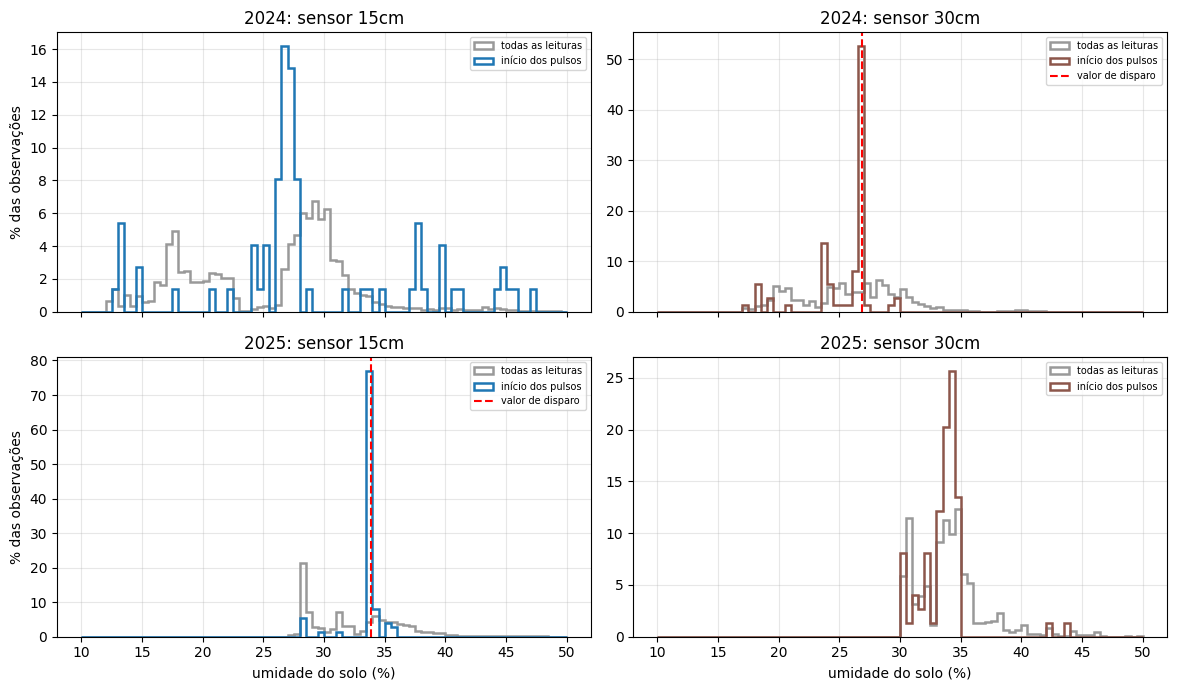

In [15]:
BINS = np.arange(10, 50.5, 0.5)

fig, eixos = plt.subplots(len(ANOS), len(PROFS), figsize=(12, 7), sharex=True)

for i, ano in enumerate(ANOS):
    leituras = serie[(serie["ano"] == ano) & serie["valido"]]
    disparos = pulsos[(pulsos["ano"] == ano) & pulsos["dia_valido"]]

    for j, prof in enumerate(PROFS):
        ax = eixos[i, j]
        for valores, cor, rotulo in [
            (leituras[f"umidade_{prof}"].dropna(), "0.6", "todas as leituras"),
            (disparos[f"umidade_{prof}"].dropna(), CORES[prof], "início dos pulsos"),
        ]:
            ax.hist(valores, bins=BINS, weights=np.full(len(valores), 100 / len(valores)),
                    histtype="step", lw=1.8, color=cor, label=rotulo)
        if gatilho.loc[ano, "profundidade"] == prof:
            ax.axvline(gatilho.loc[ano, "valor_mais_frequente_no_disparo"], color="red", ls="--", label="valor de disparo")
        ax.set_title(f"{ano}: sensor {prof}")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=7)

for ax in eixos[-1]:
    ax.set_xlabel("umidade do solo (%)")
for ax in eixos[:, 0]:
    ax.set_ylabel("% das observações")

fig.tight_layout()
salvar_fig(fig, "06_umidade_no_disparo.png")
plt.show()

**Valor de disparo:**

- 2024: a irrigação começa quando o sensor de **30 cm** chega a ~26,9%. 58% dos disparos ficam a até 0,5 ponto desse valor, contra 10% das leituras em geral.
- 2025: a irrigação começa quando o sensor de **15 cm** chega a ~33,9%. 82% dos disparos ficam perto desse valor, contra 9% das leituras.

Ou seja, o controlador mudou de sensor e de limiar de um ano para o outro.

**A regra funciona?** No período válido inteiro, não parece: a umidade fica abaixo do limiar em 55% do tempo e quase nunca há irrigação. Isso acontece por causa das semanas iniciais em que o controlador estava desligado. Dentro da fase automática, a regra explica a válvula: quando a umidade cruza o limiar para baixo, a irrigação começa em até 40 min em 98% dos casos, nos dois anos.

A versão "umidade abaixo do limiar → irriga" acerta menos (64% e 76%). Provavelmente o controlador espera a água infiltrar depois de um pulso antes de decidir se repete.

## 7. Resposta do solo à irrigação

Cada episódio é alinhado no instante em que começa. A curva mostra quanto a umidade mudou em relação à leitura logo antes (mediana e faixa entre os quartis).

In [16]:
JANELA = range(-60, 241, 10)  # minutos em relação ao início do episódio
passo = pd.Timedelta(FREQ)

inicios = (
    pulsos[pulsos["dia_valido"]]
    .groupby("episodio")
    .agg(inicio=("inicio", "min"), ano=("ano", "first"), pulsos=("inicio", "size"))
)

curvas_resp, picos = [], []

for ep, e in inicios.iterrows():
    t0 = e["inicio"].floor(FREQ)
    for prof in PROFS:
        u = serie[f"umidade_{prof}"]
        base = u.get(t0 - passo, np.nan)
        if np.isnan(base):
            continue

        delta = pd.Series(u.reindex([t0 + pd.Timedelta(minutes=m) for m in JANELA]).to_numpy() - base, index=list(JANELA))
        curvas_resp.append(pd.DataFrame({"ano": e["ano"], "profundidade": prof, "minutos": delta.index, "delta": delta.to_numpy()}))

        depois = delta[delta.index >= 0].dropna()
        if len(depois):
            picos.append({
                "episodio": ep, "ano": e["ano"], "profundidade": prof, "pulsos": e["pulsos"],
                "umidade_antes": base, "delta_pico": depois.max(), "min_ate_pico": depois.idxmax(),
                "delta_apos_4h": depois.iloc[-1],
            })

curvas_resp = pd.concat(curvas_resp, ignore_index=True)
picos = pd.DataFrame(picos)
salvar_csv(picos, "07_resposta_por_episodio.csv")

picos.groupby(["ano", "profundidade"])[["delta_pico", "min_ate_pico", "delta_apos_4h"]].median()

delta_pico  min_ate_pico  delta_apos_4h
ano  profundidade                                         
2024 15cm               13.18          30.0           3.77
     30cm                8.06          40.0           2.79
2025 15cm               12.50          40.0           2.43
     30cm                0.23          85.0           0.10

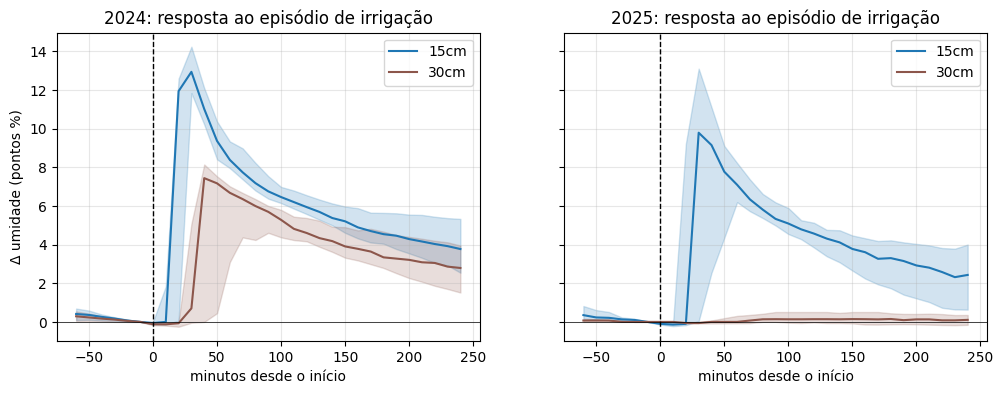

In [17]:
fig, eixos = plt.subplots(1, len(ANOS), figsize=(12, 4), sharey=True)

for ax, ano in zip(eixos, ANOS):
    for prof in PROFS:
        c = curvas_resp.query("ano == @ano and profundidade == @prof")
        q = c.groupby("minutos")["delta"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.plot(q.index, q[0.5], color=CORES[prof], label=prof)
        ax.fill_between(q.index, q[0.25], q[0.75], color=CORES[prof], alpha=0.2)
    ax.axvline(0, color="k", lw=1, ls="--")
    ax.axhline(0, color="k", lw=0.5)
    ax.set(title=f"{ano}: resposta ao episódio de irrigação", xlabel="minutos desde o início")
    ax.grid(alpha=0.3)
    ax.legend()

eixos[0].set_ylabel("Δ umidade (pontos %)")
salvar_fig(fig, "07_resposta_irrigacao.png")
plt.show()

- **15 cm:** sobe 12 a 13 pontos, com pico 30 a 40 min depois do início, e ainda está 2 a 4 pontos acima depois de 4 h.
- **30 cm:** em 2024 sobe 8 pontos, com ~10 min de atraso em relação ao de 15 cm. Em 2025 praticamente não reage (+0,2).

Isso é coerente com a regra da seção 6. Em 2024 o controlador olhava o sensor de 30 cm, então irrigava até a água chegar lá (volume por pulso maior). Em 2025 olhava o de 15 cm e parava antes.

Para o nosso sistema, o sensor de 15 cm é o que mostra rápido o efeito da irrigação.

## 8. Secagem e ambiente

A taxa de secagem é a variação da umidade em 3 h (%/h), considerando só trechos sem irrigação nessas 3 h e nas 2 h anteriores. Uso 3 h porque o sensor tem resolução baixa: em 10 min a leitura quase sempre fica igual.

A relação com o ambiente é medida pela correlação de Spearman, que é menos sensível a esses degraus do sensor.

In [18]:
JANELA_H, SEM_IRRIGAR_H = 3, 2

partes = []
for ano, s in serie.groupby("ano"):
    s = s.copy()
    livre = s["valvula"].fillna(0).rolling((JANELA_H + SEM_IRRIGAR_H) * 6).max() == 0
    for prof in PROFS:
        u = s[f"umidade_{prof}"]
        s[f"taxa_{prof}"] = ((u - u.shift(JANELA_H * 6)) / JANELA_H).where(livre & s["valido"])
    partes.append(s)

secagem = pd.concat(partes)
secagem["hora"] = secagem.index.hour
taxas = [f"taxa_{p}" for p in PROFS]

resumo_secagem = secagem.groupby("ano")[taxas].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).T
salvar_csv(resumo_secagem, "08_taxa_secagem.csv", index=True)
resumo_secagem.round(3)

ano                  2024      2025
taxa_15cm count  10535.00  10334.00
          mean      -0.09     -0.07
          std        0.35      0.63
          min       -9.62     -9.42
          10%       -0.27     -0.27
          25%       -0.11     -0.10
          50%       -0.04     -0.02
          75%       -0.01      0.00
          90%        0.01      0.04
          max        2.75      9.23
taxa_30cm count  10353.00  10348.00
          mean      -0.07     -0.02
          std        0.39      0.56
          min      -10.05    -10.46
          10%       -0.25     -0.10
          25%       -0.10     -0.04
          50%       -0.04      0.00
          75%        0.00      0.00
          90%        0.01      0.03
          max        3.48      6.96

In [19]:
correl = []
for ano, g in secagem.groupby("ano"):
    for taxa in taxas:
        for var in ["ar_temperatura", "ar_umidade", "vpd_kpa", "temp_solo_15cm"]:
            par = g[[taxa, var]].dropna()
            correl.append({"ano": ano, "taxa": taxa, "variavel": var, "spearman": par[taxa].corr(par[var], method="spearman")})

correl = pd.DataFrame(correl)
salvar_csv(correl, "08_correlacao_secagem_ambiente.csv")
correl.pivot_table(index=["ano", "taxa"], columns="variavel", values="spearman").round(2)

variavel        ar_temperatura  ar_umidade  temp_solo_15cm  vpd_kpa
ano  taxa                                                          
2024 taxa_15cm           -0.04        0.01            0.17    -0.03
     taxa_30cm           -0.13        0.09            0.15    -0.11
2025 taxa_15cm            0.00       -0.02            0.18     0.01
     taxa_30cm           -0.32        0.28            0.17    -0.30

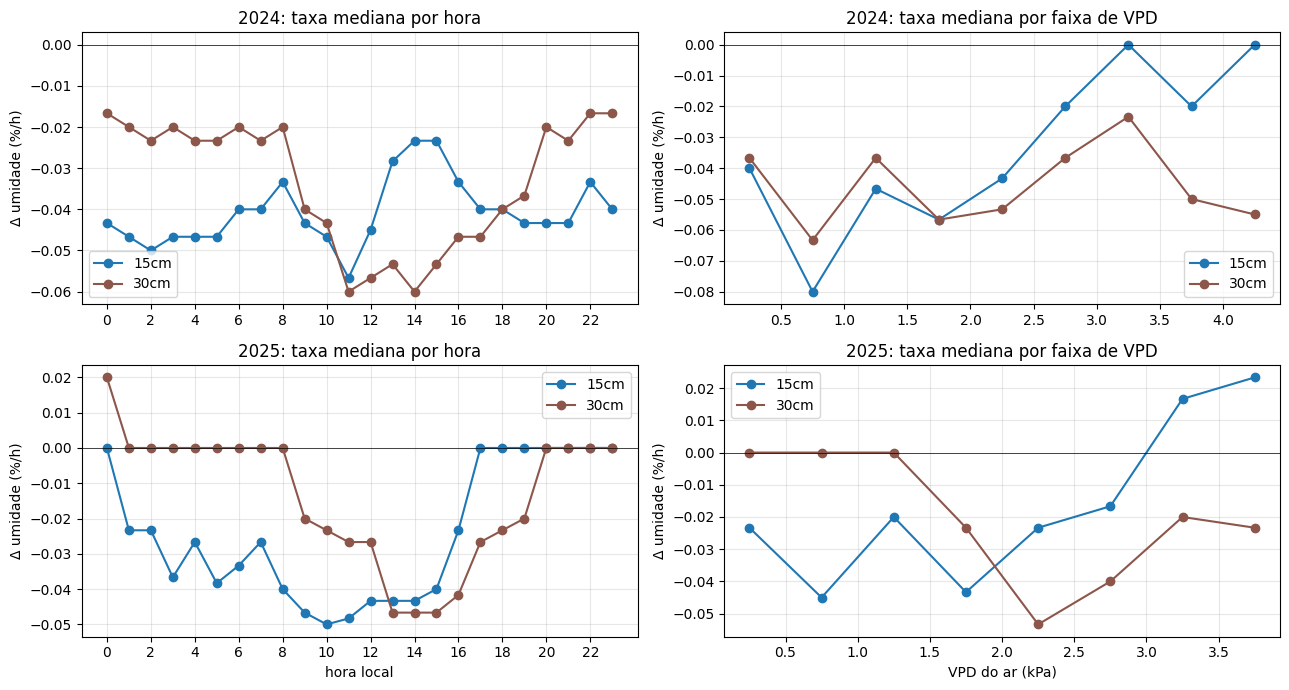

In [20]:
secagem["faixa_vpd"] = pd.cut(secagem["vpd_kpa"], bins=np.arange(0, 5.5, 0.5))

fig, eixos = plt.subplots(len(ANOS), 2, figsize=(13, 7))

for i, ano in enumerate(ANOS):
    g = secagem[secagem["ano"] == ano]
    for prof in PROFS:
        por_hora = g.groupby("hora")[f"taxa_{prof}"].median()
        eixos[i, 0].plot(por_hora.index, por_hora, marker="o", color=CORES[prof], label=prof)

        por_vpd = g.groupby("faixa_vpd", observed=True)[f"taxa_{prof}"].agg(["median", "count"]).query("count >= 30")
        eixos[i, 1].plot([f.mid for f in por_vpd.index], por_vpd["median"], marker="o", color=CORES[prof], label=prof)

    eixos[i, 0].set(title=f"{ano}: taxa mediana por hora", xticks=range(0, 24, 2))
    eixos[i, 1].set(title=f"{ano}: taxa mediana por faixa de VPD")
    for ax in eixos[i]:
        ax.axhline(0, color="k", lw=0.5)
        ax.set_ylabel("Δ umidade (%/h)")
        ax.grid(alpha=0.3)
        ax.legend()

eixos[-1, 0].set_xlabel("hora local")
eixos[-1, 1].set_xlabel("VPD do ar (kPa)")
fig.tight_layout()
salvar_fig(fig, "08_secagem_hora_vpd.png")
plt.show()

Sem irrigação o solo seca devagar: mediana de 0,02 a 0,04 ponto por hora, ou ~1 ponto por dia. A secagem se concentra entre 8h e 16h.

Nessa escala, a relação direta com temperatura, umidade do ar e VPD é fraca (|ρ| ≤ 0,3, e perto de 0 no sensor de 15 cm). A variação em 3 h é da mesma ordem da resolução do sensor, então o sinal fica ruidoso e o gráfico por VPD oscila bastante. As variáveis do ar aparecem com mais força na seção 9, como indicador de quando a irrigação vai ser necessária.

## 9. Alvo do classificador

Há dois alvos possíveis:

1. **`irrigando`**: a válvula está aberta agora. Prever isso é copiar o controlador. Como o controlador decide por limiar, o modelo só reaprenderia o limiar.
2. **`alvo_irrigar_prox`**: um episódio de irrigação começa nos próximos 60 min. Esse alvo é antecipatório e permite agir antes de o solo chegar ao limite.

**O alvo escolhido é o segundo.** Para ele, entram só os instantes com a válvula fechada e só a **fase automática**. Fora dela o solo fica seco sem irrigação, e o rótulo "não irrigar" estaria errado.

Todas as features usam apenas informação do passado. As features do protótipo são as que vamos ter na prática: umidade do solo (15 cm), temperatura e umidade do ar, e o que dá para derivar delas.

In [21]:
HORIZONTE_MIN = 60

FEATURES_PROTOTIPO = [
    "umidade_15cm", "delta_umidade_15cm_30min", "delta_umidade_15cm_60min", "delta_umidade_15cm_180min",
    "ar_temperatura", "ar_umidade", "vpd_kpa", "hora_sin", "hora_cos", "min_desde_ultima_irrigacao",
]
FEATURES_COMPLETO = FEATURES_PROTOTIPO + [
    "umidade_30cm", "delta_umidade_30cm_30min", "delta_umidade_30cm_60min", "delta_umidade_30cm_180min",
    "temp_solo_15cm", "temp_solo_30cm",
]

inicios_ep = set(pulsos.groupby("episodio")["inicio"].min().dt.floor(FREQ))

partes = []
for ano, s in serie.groupby("ano"):
    s = s.copy()

    # tendência recente da umidade
    for prof in PROFS:
        for m in (30, 60, 180):
            s[f"delta_umidade_{prof}_{m}min"] = s[f"umidade_{prof}"].diff(m // 10)

    # hora cíclica: 23h fica perto de 0h
    hora = s.index.hour + s.index.minute / 60
    s["hora_sin"] = np.sin(2 * np.pi * hora / 24)
    s["hora_cos"] = np.cos(2 * np.pi * hora / 24)

    # minutos desde a última vez que a válvula esteve aberta (máx. 48 h)
    ultima = pd.Series(s.index.where(s["valvula"].fillna(0) > 0), index=s.index).ffill()
    s["min_desde_ultima_irrigacao"] = ((s.index - ultima).dt.total_seconds() / 60).fillna(2880).clip(upper=2880)

    # alvos
    s["irrigando"] = (s["valvula"].fillna(0) > 0).astype(int)
    comeca = pd.Series(s.index.isin(list(inicios_ep)), index=s.index).astype(int)
    passos = HORIZONTE_MIN // 10
    s["alvo_irrigar_prox"] = comeca[::-1].rolling(passos, min_periods=1).max()[::-1].shift(-1).fillna(0).astype(int)

    s["fase_automatica"] = (s.index >= FASES[ano][0]) & (s.index <= FASES[ano][1])
    partes.append(s)

dataset = pd.concat(partes)
dataset = dataset[dataset["valido"]]

base = dataset[(dataset["irrigando"] == 0) & dataset["fase_automatica"]]

base.groupby("ano")["alvo_irrigar_prox"].agg(instantes="size", positivos="sum", pct_positivos=lambda x: 100 * x.mean())

,instantes,positivos,pct_positivos
ano,,,
2024,4123,234,5.68
2025,3760,324,8.62


Quanto cada variável, sozinha, separa as duas classes? A AUC vai de 0,5 (não separa nada) a 1 (separa perfeitamente). O sinal indica se a variável é mais alta (+) ou mais baixa (−) antes de uma irrigação.

In [22]:
auc = []
for ano, g in base.groupby("ano"):
    for f in FEATURES_COMPLETO:
        x = g[[f, "alvo_irrigar_prox"]].dropna()
        a = roc_auc_score(x["alvo_irrigar_prox"], x[f])
        auc.append({"ano": ano, "feature": f, "auc": max(a, 1 - a), "sinal": "+" if a >= 0.5 else "−"})

auc = pd.DataFrame(auc)
tabela_auc = auc.pivot_table(index="feature", columns="ano", values="auc").join(
    auc.pivot_table(index="feature", columns="ano", values="sinal", aggfunc="first").add_prefix("sinal_")
).sort_values(ANOS[-1], ascending=False)

salvar_csv(tabela_auc, "09_auc_por_feature.csv", index=True)
tabela_auc.round(3)

ano,2024,2025,sinal_2024,sinal_2025
feature,,,,
umidade_15cm,0.89,0.94,−,−
hora_cos,0.83,0.77,−,−
ar_temperatura,0.80,0.77,+,+
vpd_kpa,0.79,0.76,+,+
delta_umidade_30cm_180min,0.78,0.76,−,−
delta_umidade_30cm_60min,0.70,0.75,−,−
ar_umidade,0.75,0.74,−,−
delta_umidade_15cm_180min,0.76,0.71,−,−
delta_umidade_30cm_30min,0.67,0.70,−,−


Os positivos são 6% (2024) e 9% (2025) dos instantes. As classes são desbalanceadas, mas não de forma extrema.

- A variável que mais separa é a umidade a 15 cm (AUC 0,89 e 0,94). É o esperado, já que o controlador decide por limiar.
- Em seguida vêm hora do dia, temperatura do ar e VPD (0,76 a 0,83): a irrigação costuma ser necessária nas horas quentes da tarde.
- A queda da umidade nas últimas 3 h também ajuda (0,71 a 0,78).
- A umidade a 30 cm separa muito bem em 2024 (0,93), quando era o sensor de gatilho, e pouco em 2025 (0,65).

## 10. A umidade absoluta serve de um ano para o outro?

Antes de levar o modelo para outro sensor e outro solo, é preciso saber se o que ele aprende num cenário vale em outro. Os dois anos de Parma servem de teste: o controlador usou sensor e limiar diferentes em cada um.

O teste usa modelos simples e as features desta seção, com a umidade em % absoluto:

- **limiar:** "irrigar se `umidade_15cm` ≤ L", com L escolhido no treino;
- **regressão logística** com as classes balanceadas;
- **árvore de decisão** rasa (profundidade 3), para dar para ler as regras.

As divisões são temporais, sem embaralhar: os primeiros 70% de cada ano para treino e os 30% finais para teste, e treino em um ano com teste no outro.

In [23]:
def limiar_otimo(x, y):
    candidatos = np.unique(np.round(x, 1))
    return candidatos[np.argmax([f1_score(y, (x <= c).astype(int), zero_division=0) for c in candidatos])]


def metricas(y, pred, score):
    return {
        "precisao": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "acuracia_bal": balanced_accuracy_score(y, pred),
        "auc": roc_auc_score(y, score),
    }


cenarios = []
for ano in ANOS:
    g = base[base["ano"] == ano]
    corte = g.index[int(len(g) * 0.7)]
    cenarios.append((f"{ano} 70/30", g[g.index < corte], g[g.index >= corte]))
cenarios += [
    (f"{ANOS[0]} → {ANOS[1]}", base[base["ano"] == ANOS[0]], base[base["ano"] == ANOS[1]]),
    (f"{ANOS[1]} → {ANOS[0]}", base[base["ano"] == ANOS[1]], base[base["ano"] == ANOS[0]]),
]

resultados, arvores = [], {}

for nome_feat, feats in [("protótipo", FEATURES_PROTOTIPO), ("completo", FEATURES_COMPLETO)]:
    for nome, treino, teste in cenarios:
        treino, teste = treino.dropna(subset=feats), teste.dropna(subset=feats)
        Xtr, ytr, Xte, yte = treino[feats], treino["alvo_irrigar_prox"], teste[feats], teste["alvo_irrigar_prox"]
        info = {"features": nome_feat, "cenario": nome, "positivos_teste": int(yte.sum())}

        L = limiar_otimo(Xtr["umidade_15cm"].to_numpy(), ytr)
        resultados.append({**info, "modelo": f"limiar (≤ {L})", **metricas(yte, (Xte["umidade_15cm"] <= L).astype(int), -Xte["umidade_15cm"])})

        log = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)).fit(Xtr, ytr)
        resultados.append({**info, "modelo": "logística", **metricas(yte, log.predict(Xte), log.predict_proba(Xte)[:, 1])})

        arv = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=0).fit(Xtr, ytr)
        resultados.append({**info, "modelo": "árvore", **metricas(yte, arv.predict(Xte), arv.predict_proba(Xte)[:, 1])})
        arvores[(nome_feat, nome)] = export_text(arv, feature_names=feats, decimals=2)

resultados = pd.DataFrame(resultados)
salvar_csv(resultados, "10_baselines.csv")
resultados.set_index(["features", "cenario", "modelo"]).round(3)

positivos_teste  precisao  recall    f1  acuracia_bal   auc
features  cenario     modelo                                                                      
protótipo 2024 70/30  limiar (≤ 26.9)               70      1.00    0.01  0.03          0.51  0.96
                      logística                     70      0.32    0.76  0.45          0.83  0.89
                      árvore                        70      0.64    0.70  0.67          0.84  0.84
          2025 70/30  limiar (≤ 34.2)              135      0.77    0.52  0.62          0.75  0.94
                      logística                    135      0.58    0.96  0.72          0.93  0.99
                      árvore                       135      0.62    0.83  0.71          0.88  0.91
          2024 → 2025 limiar (≤ 27.8)              291      0.00    0.00  0.00          0.50  0.94
                      logística                    291      0.20    0.02  0.03          0.51  0.93
                      árvore                       291      0.08    0.02  0.03          0.50  0.49
          2025 → 2024 limiar (≤ 34.2)              208      0.06    1.00  0.11          0.52  0.88
                      logística                    208      0.06    1.00  0.11          0.52  0.93
                      árvore                       208      0.06    1.00  0.12          0.56  0.80
completo  2024 70/30  limiar (≤ 26.9)               69      1.00    0.01  0.03          0.51  0.96
                      logística                     69      0.34    0.84  0.48          0.87  0.94
                      árvore                        69      0.45    0.84  0.59          0.89  0.89
          2025 70/30  limiar (≤ 34.2)              129      0.76    0.52  0.62          0.75  0.94
                      logística                    129      0.56    0.95  0.70          0.92  0.98
                      árvore                       129      0.73    0.78  0.75          0.87  0.88
          2024 → 2025 limiar (≤ 27.8)              273      0.00    0.00  0.00          0.50  0.94
                      logística                    273      0.00    0.00  0.00          0.50  0.73
                      árvore                       273      0.52    0.06  0.10          0.53  0.53
          2025 → 2024 limiar (≤ 34.2)              202      0.06    1.00  0.11          0.52  0.88
                      logística                    202      0.06    1.00  0.11          0.52  0.84
                      árvore                       202      0.06    1.00  0.12          0.55  0.80

In [24]:
print(arvores[("protótipo", f"{ANOS[0]} → {ANOS[1]}")])

|--- umidade_15cm <= 28.32
|   |--- ar_temperatura <= 26.35
|   |   |--- ar_umidade <= 75.50
|   |   |   |--- class: 1
|   |   |--- ar_umidade >  75.50
|   |   |   |--- class: 0
|   |--- ar_temperatura >  26.35
|   |   |--- hora_cos <= 0.07
|   |   |   |--- class: 1
|   |   |--- hora_cos >  0.07
|   |   |   |--- class: 0
|--- umidade_15cm >  28.32
|   |--- delta_umidade_15cm_30min <= 3.45
|   |   |--- ar_temperatura <= 17.50
|   |   |   |--- class: 0
|   |   |--- ar_temperatura >  17.50
|   |   |   |--- class: 0
|   |--- delta_umidade_15cm_30min >  3.45
|   |   |--- class: 0



**Dentro do mesmo ano** o alvo é bem previsível. Com as features do protótipo, a regressão logística chega a AUC 0,89 (2024) e 0,99 (2025), e a árvore a F1 de ~0,7. A árvore aprende basicamente "umidade a 15 cm baixa + calor/tarde".

**Entre anos** não funciona (F1 perto de 0). O limiar aprendido em 2024 (umidade ≤ 27,8) quase nunca acontece em 2025, e o de 2025 (≤ 34,2) dispara o tempo todo em 2024. O AUC continua alto (0,88 a 0,94): o modelo ordena bem os instantes mais secos, mas o valor de corte em % absoluto muda com o sensor, a profundidade e o limiar.

**Decisão para o modelo:** a umidade entra como posição em relação ao limiar, `dist_limiar = (umidade − limiar) / escala`, a tendência é dividida pela mesma escala e a hora vira hora solar. Com isso, no notebook do modelo, treinar em um ano e testar no outro mantém AP de 0,83 a 0,86.

## 11. Conclusões

1. Na linha 3 a irrigação acompanha a umidade do solo nos dois anos (~75 pulsos por ano).
2. O sensor `901b` está a 15 cm e o `2f2b` a 30 cm.
3. A regra do controlador foi reconstruída a partir dos dados:
   - 2024: irriga quando a umidade a 30 cm cai para 26,9%;
   - 2025: irriga quando a umidade a 15 cm cai para 33,9%.

   Ela só vale na fase automática (04/08 a 03/09/2024 e 23/07 a 19/08/2025).
4. O sensor de 15 cm reage à irrigação em 30 a 40 min (+12 pontos). O de 30 cm reage mais tarde e só quando a irrigação é maior.
5. Sem irrigação o solo perde ~1 ponto por dia, quase tudo nas horas de sol.
6. A umidade em % absoluto não serve de um ano para o outro, porque o valor de corte depende do sensor e do limiar.

### Decisões levadas para o modelo

| | Decisão | Motivo |
|---|---|---|
| Alvo | começar uma irrigação nos próximos 60 min | antecipa a decisão em vez de copiar o limiar (seção 9) |
| Dados | linha 3, 2024 e 2025, só a fase automática, válvula fechada | fora da fase o rótulo é enganoso (seção 6) |
| Sensor | o de gatilho de cada ano (30 cm em 2024, 15 cm em 2025) | é o que o controlador olhava (seção 6) |
| Umidade | relativa ao limiar: `(umidade − limiar) / escala` | o valor absoluto não transfere (seção 10) |
| Hora | hora solar | Parma e Fortaleza têm fuso e meio-dia solar diferentes |

O modelo, a validação, a exportação para o ESP32 e o uso em Fortaleza estão em `codes/linha3 - umidade/modelo_linha3/modelo_irrigacao.ipynb`.

**Pendência:** confirmar a unidade do hidrômetro (o README diz m³, mas a escala do contador não combina) e, se possível, a descrição oficial dos regimes de irrigação ([Mendeley, DOI 10.17632/h8sfcf9487.1](https://doi.org/10.17632/h8sfcf9487.1)).